In [6]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv("financial_regression.csv")

In [8]:
df.head()

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,nasdaq close,nasdaq volume,nasdaq high-low,us_rates_%,CPI,usd_chf,eur_usd,GDP,silver open,silver high,silver low,silver close,silver volume,silver high-low,oil open,oil high,oil low,oil close,oil volume,oil high-low,platinum open,platinum high,platinum low,platinum close,platinum volume,platinum high-low,palladium open,palladium high,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume
0,2010-01-14,114.49,115.14,114.42,114.93,115646960.0,0.72,46.26,46.520,46.22,46.39,75209000.0,0.300,NaN,NaN,1.0206,1.4478,NaN,18.58,18.70,18.45,18.66,69804.0,0.25,39.30,39.4400,38.88,39.06,8575821.0,0.5600,160.13,161.85,159.7200,161.45,228500.0,2.1300,43.93,45.02,43.86,44.84,364528.0,1.16,111.51,112.37,110.79,112.03,18305238.0
1,2010-01-15,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,45.85,126849300.0,0.900,NaN,NaN,1.0264,1.4376,NaN,18.54,18.54,18.36,18.41,205106.0,0.18,38.97,39.0200,38.28,38.40,12615299.0,0.7400,160.68,161.25,159.5000,160.25,189900.0,1.7500,45.18,45.76,44.40,45.76,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0
2,2010-01-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010-01-19,113.62,115.13,113.59,115.06,138671890.0,1.54,45.96,46.640,45.95,46.59,84388200.0,0.690,NaN,NaN,1.0340,1.4269,NaN,18.53,18.79,18.50,18.79,130552.0,0.29,38.07,38.9499,38.03,38.93,8180157.0,0.9199,162.23,165.20,162.1722,165.12,295900.0,3.0278,46.01,47.08,45.70,46.94,629150.0,1.38,110.95,111.75,110.83,111.52,10467927.0
4,2010-01-20,114.28,114.45,112.98,113.89,216330645.0,1.47,46.27,46.604,45.43,45.92,145680000.0,1.174,NaN,NaN,1.0453,1.4094,NaN,18.31,18.31,17.78,17.86,230907.0,0.53,38.23,38.3500,37.88,37.89,11438685.0,0.4700,163.51,163.51,159.0900,163.22,438200.0,4.4200,46.59,47.31,45.17,47.05,643198.0,2.14,109.97,110.05,108.46,108.94,17534231.0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3904 entries, 0 to 3903
Data columns (total 47 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                3904 non-null   object 
 1   sp500 open          3719 non-null   float64
 2   sp500 high          3719 non-null   float64
 3   sp500 low           3719 non-null   float64
 4   sp500 close         3719 non-null   float64
 5   sp500 volume        3719 non-null   float64
 6   sp500 high-low      3719 non-null   float64
 7   nasdaq open         3719 non-null   float64
 8   nasdaq high         3719 non-null   float64
 9   nasdaq low          3719 non-null   float64
 10  nasdaq close        3719 non-null   float64
 11  nasdaq volume       3719 non-null   float64
 12  nasdaq high-low     3719 non-null   float64
 13  us_rates_%          176 non-null    float64
 14  CPI                 176 non-null    float64
 15  usd_chf             3694 non-null   float64
 16  eur_us

In [10]:
pd.set_option("display.max_columns", None)
df.head()

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,nasdaq close,nasdaq volume,nasdaq high-low,us_rates_%,CPI,usd_chf,eur_usd,GDP,silver open,silver high,silver low,silver close,silver volume,silver high-low,oil open,oil high,oil low,oil close,oil volume,oil high-low,platinum open,platinum high,platinum low,platinum close,platinum volume,platinum high-low,palladium open,palladium high,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume
0,2010-01-14,114.49,115.14,114.42,114.93,115646960.0,0.72,46.26,46.520,46.22,46.39,75209000.0,0.300,NaN,NaN,1.0206,1.4478,NaN,18.58,18.70,18.45,18.66,69804.0,0.25,39.30,39.4400,38.88,39.06,8575821.0,0.5600,160.13,161.85,159.7200,161.45,228500.0,2.1300,43.93,45.02,43.86,44.84,364528.0,1.16,111.51,112.37,110.79,112.03,18305238.0
1,2010-01-15,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,45.85,126849300.0,0.900,NaN,NaN,1.0264,1.4376,NaN,18.54,18.54,18.36,18.41,205106.0,0.18,38.97,39.0200,38.28,38.40,12615299.0,0.7400,160.68,161.25,159.5000,160.25,189900.0,1.7500,45.18,45.76,44.40,45.76,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0
2,2010-01-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010-01-19,113.62,115.13,113.59,115.06,138671890.0,1.54,45.96,46.640,45.95,46.59,84388200.0,0.690,NaN,NaN,1.0340,1.4269,NaN,18.53,18.79,18.50,18.79,130552.0,0.29,38.07,38.9499,38.03,38.93,8180157.0,0.9199,162.23,165.20,162.1722,165.12,295900.0,3.0278,46.01,47.08,45.70,46.94,629150.0,1.38,110.95,111.75,110.83,111.52,10467927.0
4,2010-01-20,114.28,114.45,112.98,113.89,216330645.0,1.47,46.27,46.604,45.43,45.92,145680000.0,1.174,NaN,NaN,1.0453,1.4094,NaN,18.31,18.31,17.78,17.86,230907.0,0.53,38.23,38.3500,37.88,37.89,11438685.0,0.4700,163.51,163.51,159.0900,163.22,438200.0,4.4200,46.59,47.31,45.17,47.05,643198.0,2.14,109.97,110.05,108.46,108.94,17534231.0


In [11]:
#เลือกข้อมูลที่สนใจและแปลง Type date ที่เป็น object เป็น datetime64
df_sp500 = df[['date', 'sp500 open' , 'sp500 low' , "sp500 high" , 'sp500 close', 'sp500 volume']]
df_sp500['date'] = pd.to_datetime(df_sp500['date'])

C:\Users\por-n\AppData\Local\Temp\ipykernel_7284\3042865874.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sp500['date'] = pd.to_datetime(df_sp500['date'])


In [12]:
df_sp500.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3904 entries, 0 to 3903
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          3904 non-null   datetime64[ns]
 1   sp500 open    3719 non-null   float64       
 2   sp500 low     3719 non-null   float64       
 3   sp500 high    3719 non-null   float64       
 4   sp500 close   3719 non-null   float64       
 5   sp500 volume  3719 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 183.1 KB


In [13]:
# หาช่วงเวลาของข้อมูล
df_sp500['date'].min(), df_sp500['date'].max()

(Timestamp('2010-01-14 00:00:00'), Timestamp('2024-10-23 00:00:00'))

In [14]:
# check ค่า null 
df_sp500.isnull().sum()

date              0
sp500 open      185
sp500 low       185
sp500 high      185
sp500 close     185
sp500 volume    185
dtype: int64

In [15]:
df_sp500.dropna(inplace=True)

C:\Users\por-n\AppData\Local\Temp\ipykernel_7284\186369666.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sp500.dropna(inplace=True)


In [16]:
# check ค่า อีกที
df_sp500.isnull().sum()

date            0
sp500 open      0
sp500 low       0
sp500 high      0
sp500 close     0
sp500 volume    0
dtype: int64

In [25]:
# check ข้อมูล ซํ้า
df_sp500.duplicated().sum()

0

In [26]:
df_sp500.head()

,date,sp500 open,sp500 low,sp500 high,sp500 close,sp500 volume
0,2010-01-14,114.49,114.42,115.14,114.93,115646960.0
1,2010-01-15,114.73,113.20,114.84,113.64,212252769.0
3,2010-01-19,113.62,113.59,115.13,115.06,138671890.0
4,2010-01-20,114.28,112.98,114.45,113.89,216330645.0
5,2010-01-21,113.92,111.56,114.27,111.70,344747028.0


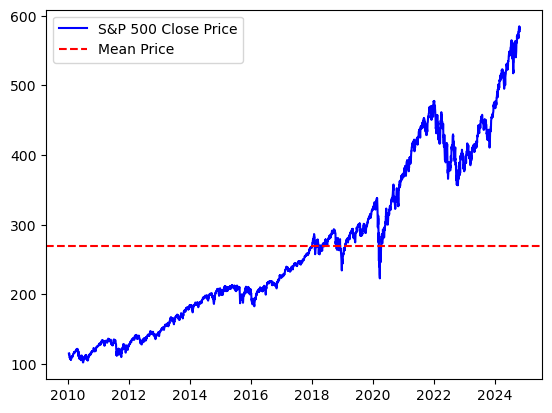

In [17]:
import matplotlib.pyplot as plt
plt.plot(df_sp500['date'], df_sp500['sp500 close'], label='S&P 500 Close Price', color='blue')
plt.axhline(df_sp500['sp500 close'].mean(), color='red', linestyle='dashed', label='Mean Price')
plt.legend()
plt.show()

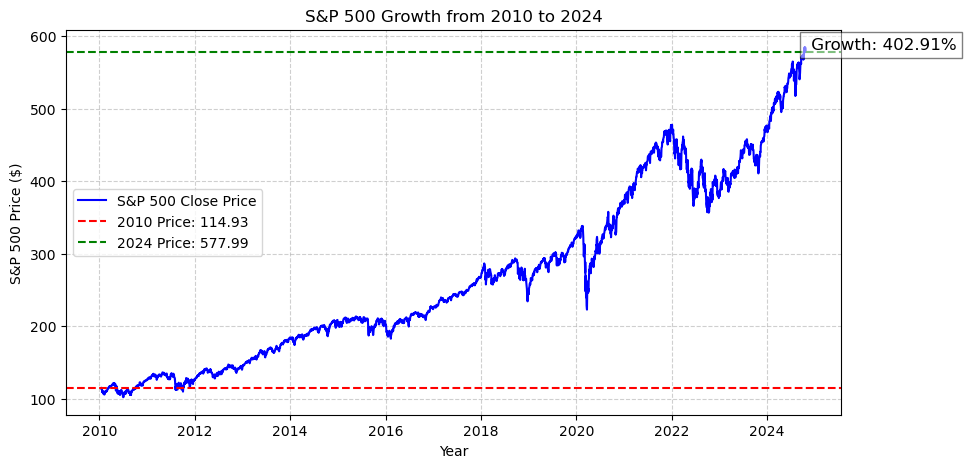

In [28]:
plt.figure(figsize=(10,5))
plt.plot(df_sp500['date'], df_sp500['sp500 close'], label="S&P 500 Close Price", color='blue')

# เพิ่มเส้นแนวนอนแสดงราคาเริ่มต้นและปัจจุบัน
plt.axhline(initial_value, color='red', linestyle='dashed', label=f"2010 Price: {initial_value:.2f}")
plt.axhline(final_value, color='green', linestyle='dashed', label=f"2024 Price: {final_value:.2f}")

# คำนวณเปอร์เซ็นต์การเติบโต
growth_percentage = ((final_value - initial_value) / initial_value) * 100

# เพิ่มข้อความแสดงเปอร์เซ็นต์การเติบโตบนกราฟ
plt.text(df_sp500['date'].iloc[-1], final_value, f" Growth: {growth_percentage:.2f}%", 
         horizontalalignment='left', verticalalignment='bottom', fontsize=12, color='black', bbox=dict(facecolor='white', alpha=0.5))

# ตั้งค่า Label และ Title
plt.xlabel("Year")
plt.ylabel("S&P 500 Price ($)")
plt.title("S&P 500 Growth from 2010 to 2024")

# แสดง Legend
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# แสดงกราฟ
plt.show()

In [29]:
#เลือกข้อมูลที่สนใจและแปลง Type date ที่เป็น object เป็น datetime64
df_nasdaq= df[['date', 'nasdaq open' , 'nasdaq low' , 'nasdaq high', 'nasdaq close' ,  'nasdaq volume']]
df_nasdaq['date'] = pd.to_datetime(df_nasdaq['date'])

C:\Users\por-n\AppData\Local\Temp\ipykernel_9208\3375083581.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nasdaq['date'] = pd.to_datetime(df_nasdaq['date'])


In [30]:
# check ค่า null 
df_nasdaq.isnull().sum()

date               0
nasdaq open      185
nasdaq low       185
nasdaq high      185
nasdaq close     185
nasdaq volume    185
dtype: int64

In [31]:
df_nasdaq.dropna(inplace=True)

C:\Users\por-n\AppData\Local\Temp\ipykernel_9208\51754090.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nasdaq.dropna(inplace=True)


In [32]:
df_nasdaq.isnull().sum()

date             0
nasdaq open      0
nasdaq low       0
nasdaq high      0
nasdaq close     0
nasdaq volume    0
dtype: int64

In [33]:
# check ข้อมูล ซํ้า
df_nasdaq.duplicated().sum()

0

In [34]:
df_nasdaq.head()

,date,nasdaq open,nasdaq low,nasdaq high,nasdaq close,nasdaq volume
0,2010-01-14,46.26,46.22,46.520,46.39,75209000.0
1,2010-01-15,46.46,45.65,46.550,45.85,126849300.0
3,2010-01-19,45.96,45.95,46.640,46.59,84388200.0
4,2010-01-20,46.27,45.43,46.604,45.92,145680000.0
5,2010-01-21,46.06,45.30,46.350,45.49,204939600.0


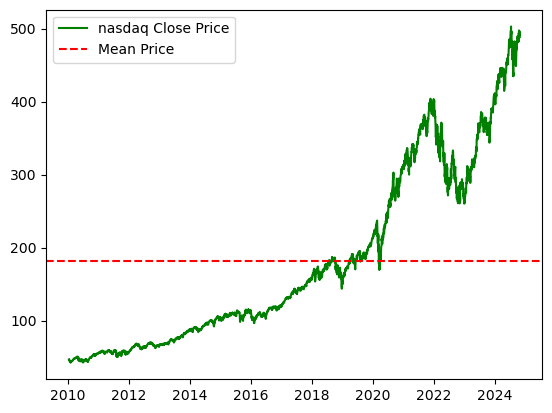

In [41]:
plt.plot(df_nasdaq['date'], df_nasdaq['nasdaq close'], label='nasdaq Close Price', color='g')
plt.axhline(df_nasdaq['nasdaq close'].mean(), color='red', linestyle='dashed', label='Mean Price')
plt.legend()
plt.show()

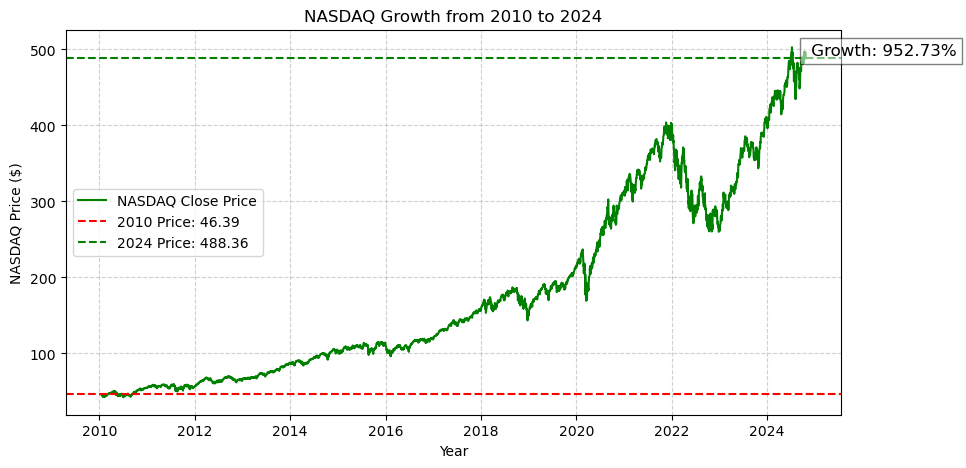

In [42]:
df_nasdaq = df[['date', 'nasdaq close']].dropna()

# แปลง 'date' เป็น datetime
df_nasdaq['date'] = pd.to_datetime(df_nasdaq['date'])

# หาค่าเริ่มต้นและค่าสุดท้ายของ NASDAQ
initial_value_nasdaq = df_nasdaq[df_nasdaq['date'].dt.year == 2010]['nasdaq close'].iloc[0]
final_value_nasdaq = df_nasdaq[df_nasdaq['date'].dt.year == 2024]['nasdaq close'].iloc[-1]

# คำนวณเปอร์เซ็นต์การเติบโต
growth_percentage_nasdaq = ((final_value_nasdaq - initial_value_nasdaq) / initial_value_nasdaq) * 100

# Plot กราฟการเติบโตของ NASDAQ
plt.figure(figsize=(10,5))
plt.plot(df_nasdaq['date'], df_nasdaq['nasdaq close'], label="NASDAQ Close Price", color='g')

# เพิ่มเส้นแนวนอนแสดงราคาเริ่มต้นและปัจจุบัน
plt.axhline(initial_value_nasdaq, color='red', linestyle='dashed', label=f"2010 Price: {initial_value_nasdaq:.2f}")
plt.axhline(final_value_nasdaq, color='green', linestyle='dashed', label=f"2024 Price: {final_value_nasdaq:.2f}")

# เพิ่มข้อความแสดงเปอร์เซ็นต์การเติบโตบนกราฟ
plt.text(df_nasdaq['date'].iloc[-1], final_value_nasdaq, f" Growth: {growth_percentage_nasdaq:.2f}%", 
         horizontalalignment='left', verticalalignment='bottom', fontsize=12, color='black', bbox=dict(facecolor='white', alpha=0.5))

# ตั้งค่า Label และ Title
plt.xlabel("Year")
plt.ylabel("NASDAQ Price ($)")
plt.title("NASDAQ Growth from 2010 to 2024")

# แสดง Legend
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# แสดงกราฟ
plt.show()

In [43]:
df_gold = df[['date', 'gold open' , 'gold low' , 'gold close', 'gold volume']]
df_gold['date'] = pd.to_datetime(df_gold['date'])

C:\Users\por-n\AppData\Local\Temp\ipykernel_9208\450233500.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_gold['date'] = pd.to_datetime(df_gold['date'])


In [44]:
df_gold.isnull().sum()

date             0
gold open      185
gold low       185
gold close     185
gold volume    185
dtype: int64

In [45]:
df_nasdaq.duplicated().sum()

0

In [46]:
df_gold.dropna(inplace=True)

C:\Users\por-n\AppData\Local\Temp\ipykernel_9208\3684490193.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_gold.dropna(inplace=True)


In [84]:
df_gold.isnull().sum()

date           0
gold open      0
gold low       0
gold close     0
gold volume    0
dtype: int64

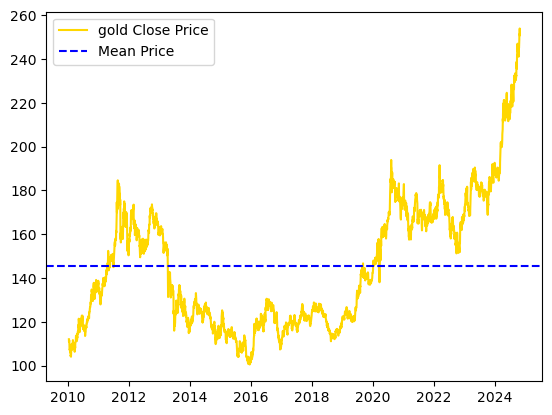

In [174]:
plt.plot(df_gold['date'], df_gold['gold close'], label='gold Close Price', color='gold')
plt.axhline(df_gold['gold close'].mean(), color='b', linestyle='dashed', label='Mean Price')
plt.legend()
plt.show()

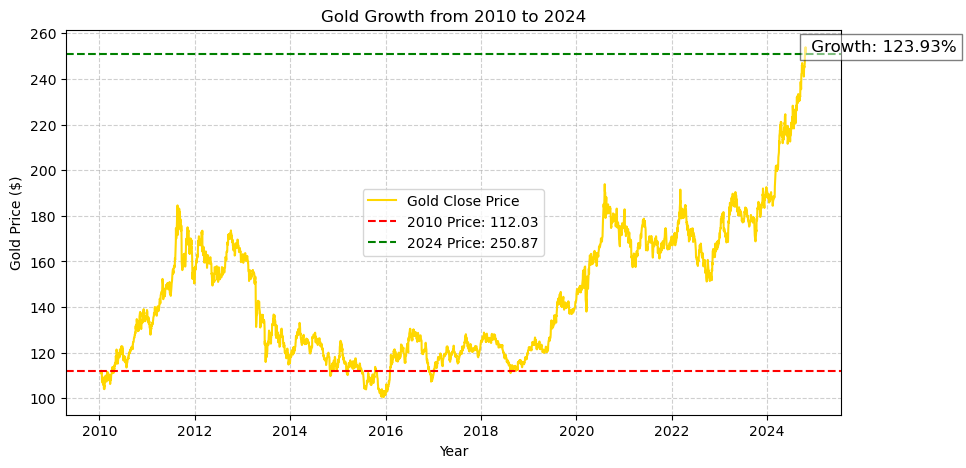

In [48]:
# % การเติบโตตั้งแต่ ปี 2010 - 2024 ของ  gold
# หาค่าเริ่มต้นและค่าสุดท้ายของ Gold
initial_value_gold = df_gold[df_gold['date'].dt.year == 2010]['gold close'].iloc[0]
final_value_gold = df_gold[df_gold['date'].dt.year == 2024]['gold close'].iloc[-1]

# คำนวณเปอร์เซ็นต์การเติบโต
growth_percentage_gold = ((final_value_gold - initial_value_gold) / initial_value_gold) * 100

# Plot กราฟการเติบโตของ Gold
plt.figure(figsize=(10,5))
plt.plot(df_gold['date'], df_gold['gold close'], label="Gold Close Price", color='gold')

# เพิ่มเส้นแนวนอนแสดงราคาเริ่มต้นและปัจจุบัน
plt.axhline(initial_value_gold, color='red', linestyle='dashed', label=f"2010 Price: {initial_value_gold:.2f}")
plt.axhline(final_value_gold, color='green', linestyle='dashed', label=f"2024 Price: {final_value_gold:.2f}")

# เพิ่มข้อความแสดงเปอร์เซ็นต์การเติบโตบนกราฟ
plt.text(df_gold['date'].iloc[-1], final_value_gold, f" Growth: {growth_percentage_gold:.2f}%", 
         horizontalalignment='left', verticalalignment='bottom', fontsize=12, color='black', bbox=dict(facecolor='white', alpha=0.5))

# ตั้งค่า Label และ Title
plt.xlabel("Year")
plt.ylabel("Gold Price ($)")
plt.title("Gold Growth from 2010 to 2024")

# แสดง Legend
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# แสดงกราฟ
plt.show()

In [51]:
df_silver = df[['date', 'silver open' , 'silver low' , 'silver close', 'silver volume']]
df_silver['date'] = pd.to_datetime(df_silver['date'])

C:\Users\por-n\AppData\Local\Temp\ipykernel_9208\1487621786.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_silver['date'] = pd.to_datetime(df_silver['date'])


In [52]:
df_silver.isnull().sum()

date               0
silver open      185
silver low       185
silver close     185
silver volume    185
dtype: int64

In [53]:
df_silver.dropna(inplace=True)

C:\Users\por-n\AppData\Local\Temp\ipykernel_9208\1407521649.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_silver.dropna(inplace=True)


In [54]:
df_silver.isnull().sum()

date             0
silver open      0
silver low       0
silver close     0
silver volume    0
dtype: int64

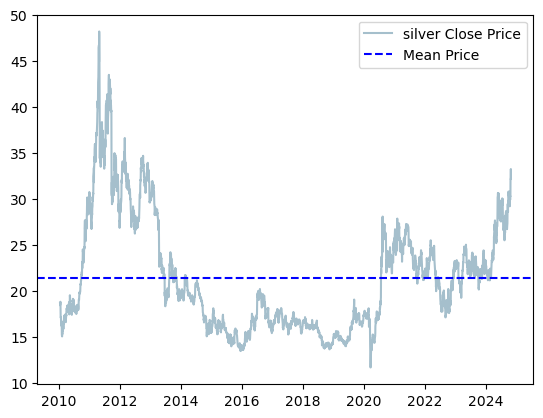

In [57]:
plt.plot(df_silver['date'], df_silver['silver close'], label='silver Close Price', color='#A5BFCC')
plt.axhline(df_silver['silver close'].mean(), color='b', linestyle='dashed', label='Mean Price')
plt.legend()
plt.show()

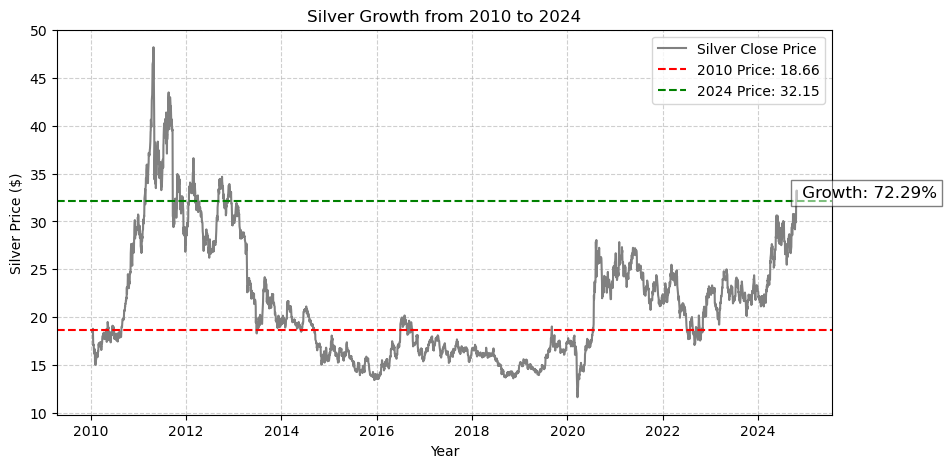

In [58]:
# % การเติบโตตั้งแต่ ปี 2010 - 2024 ของ  gold
# หาค่าเริ่มต้นและค่าสุดท้ายของ Silver
initial_value_silver = df_silver[df_silver['date'].dt.year == 2010]['silver close'].iloc[0]
final_value_silver = df_silver[df_silver['date'].dt.year == 2024]['silver close'].iloc[-1]

# คำนวณเปอร์เซ็นต์การเติบโต
growth_percentage_silver = ((final_value_silver - initial_value_silver) / initial_value_silver) * 100

# Plot กราฟการเติบโตของ Silver
plt.figure(figsize=(10,5))
plt.plot(df_silver['date'], df_silver['silver close'], label="Silver Close Price", color='gray')

# เพิ่มเส้นแนวนอนแสดงราคาเริ่มต้นและปัจจุบัน
plt.axhline(initial_value_silver, color='red', linestyle='dashed', label=f"2010 Price: {initial_value_silver:.2f}")
plt.axhline(final_value_silver, color='green', linestyle='dashed', label=f"2024 Price: {final_value_silver:.2f}")

# เพิ่มข้อความแสดงเปอร์เซ็นต์การเติบโตบนกราฟ
plt.text(df_silver['date'].iloc[-1], final_value_silver, f" Growth: {growth_percentage_silver:.2f}%", 
         horizontalalignment='left', verticalalignment='bottom', fontsize=12, color='black', bbox=dict(facecolor='white', alpha=0.5))

# ตั้งค่า Label และ Title
plt.xlabel("Year")
plt.ylabel("Silver Price ($)")
plt.title("Silver Growth from 2010 to 2024")

# แสดง Legend
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# แสดงกราฟ
plt.show()

In [98]:
df_oil = df[['date', 'oil open' , 'oil low' , 'oil close', 'oil volume']]
df_oil['date'] = pd.to_datetime(df_oil['date'])

C:\Users\por-n\AppData\Local\Temp\ipykernel_14640\916225752.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_oil['date'] = pd.to_datetime(df_oil['date'])


In [99]:
df_oil.isnull().sum()

date            0
oil open      185
oil low       185
oil close     185
oil volume    185
dtype: int64

In [100]:
df_oil.dropna(inplace=True)

C:\Users\por-n\AppData\Local\Temp\ipykernel_14640\3320674818.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_oil.dropna(inplace=True)


In [101]:
df_oil.isnull().sum()

date          0
oil open      0
oil low       0
oil close     0
oil volume    0
dtype: int64

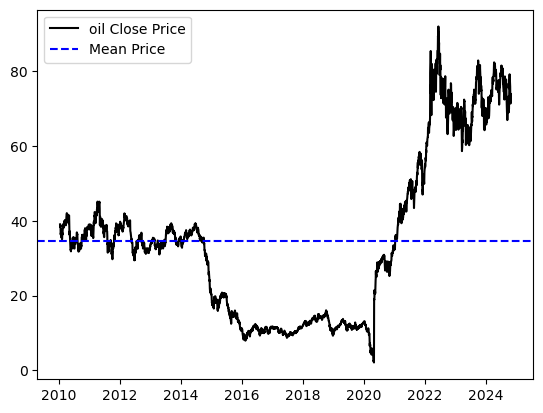

In [175]:
plt.plot(df_oil['date'], df_oil['oil close'], label='oil Close Price', color='k')
plt.axhline(df_oil['oil close'].mean(), color='b', linestyle='dashed', label='Mean Price')
plt.legend()
plt.show()

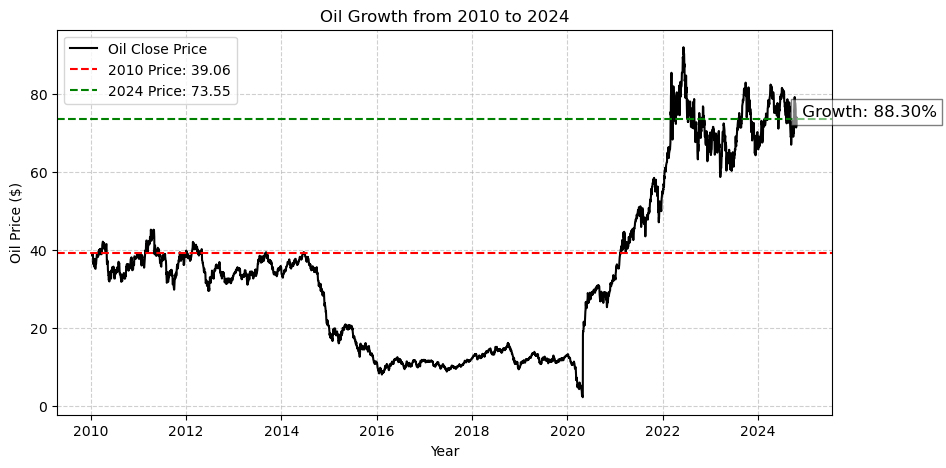

In [59]:
# % การเติบโตตั้งแต่ ปี 2010 - 2024 ของ  oil
df_oil = df[['date', 'oil close']].dropna()

# แปลง 'date' เป็น datetime
df_oil['date'] = pd.to_datetime(df_oil['date'])

# หาค่าเริ่มต้นและค่าสุดท้ายของ Oil
initial_value_oil = df_oil[df_oil['date'].dt.year == 2010]['oil close'].iloc[0]
final_value_oil = df_oil[df_oil['date'].dt.year == 2024]['oil close'].iloc[-1]

# คำนวณเปอร์เซ็นต์การเติบโต
growth_percentage_oil = ((final_value_oil - initial_value_oil) / initial_value_oil) * 100

# Plot กราฟการเติบโตของ Oil
plt.figure(figsize=(10,5))
plt.plot(df_oil['date'], df_oil['oil close'], label="Oil Close Price", color='black')

# เพิ่มเส้นแนวนอนแสดงราคาเริ่มต้นและปัจจุบัน
plt.axhline(initial_value_oil, color='red', linestyle='dashed', label=f"2010 Price: {initial_value_oil:.2f}")
plt.axhline(final_value_oil, color='green', linestyle='dashed', label=f"2024 Price: {final_value_oil:.2f}")

# เพิ่มข้อความแสดงเปอร์เซ็นต์การเติบโตบนกราฟ
plt.text(df_oil['date'].iloc[-1], final_value_oil, f" Growth: {growth_percentage_oil:.2f}%", 
         horizontalalignment='left', verticalalignment='bottom', fontsize=12, color='black', bbox=dict(facecolor='white', alpha=0.5))

# ตั้งค่า Label และ Title
plt.xlabel("Year")
plt.ylabel("Oil Price ($)")
plt.title("Oil Growth from 2010 to 2024")

# แสดง Legend
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# แสดงกราฟ
plt.show()

In [71]:
df_platinum = df[['date', 'platinum open' , 'platinum low' , 'platinum close', 'platinum volume']]
df_platinum['date'] = pd.to_datetime(df_platinum['date'])

C:\Users\por-n\AppData\Local\Temp\ipykernel_9208\2722707481.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_platinum['date'] = pd.to_datetime(df_platinum['date'])


In [72]:
df_platinum.isnull().sum()

date                 0
platinum open      185
platinum low       185
platinum close     185
platinum volume    185
dtype: int64

In [73]:
df_platinum.dropna(inplace=True)

C:\Users\por-n\AppData\Local\Temp\ipykernel_9208\2025611194.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_platinum.dropna(inplace=True)


In [74]:
df_platinum.isnull().sum()

date               0
platinum open      0
platinum low       0
platinum close     0
platinum volume    0
dtype: int64

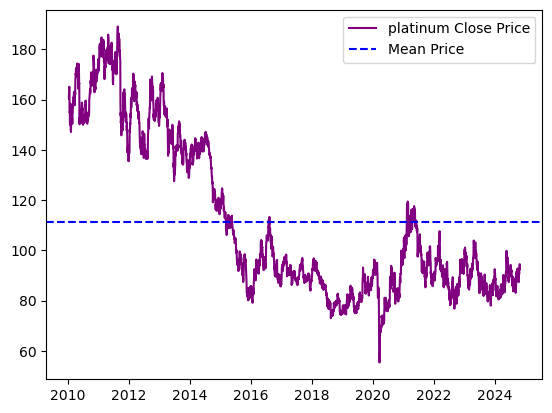

In [77]:
plt.plot(df_platinum['date'], df_platinum['platinum close'], label='platinum Close Price', color='purple')
plt.axhline(df_platinum['platinum close'].mean(), color='b', linestyle='dashed', label='Mean Price')
plt.legend()
plt.show()

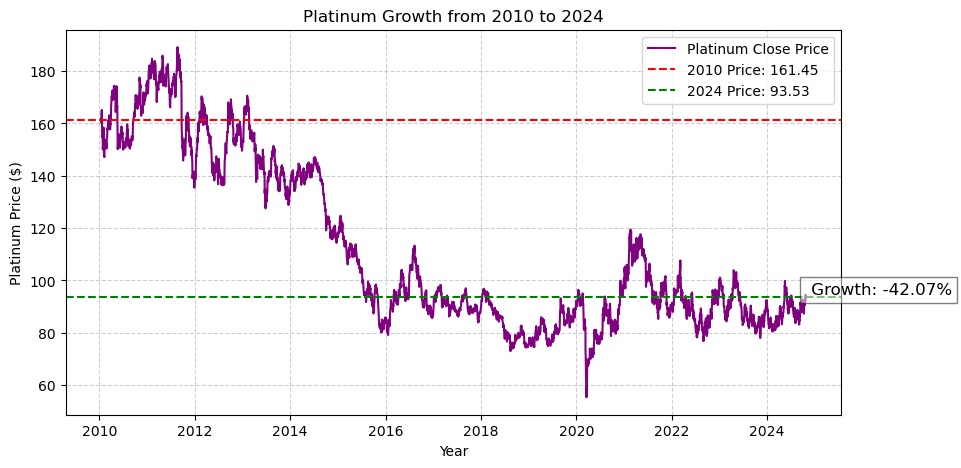

In [76]:
# % การเติบโตตั้งแต่ ปี 2010 - 2024 ของ  platinum

# หาค่าเริ่มต้นและค่าสุดท้ายของ Platinum
initial_value_platinum = df_platinum[df_platinum['date'].dt.year == 2010]['platinum close'].iloc[0]
final_value_platinum = df_platinum[df_platinum['date'].dt.year == 2024]['platinum close'].iloc[-1]

# คำนวณเปอร์เซ็นต์การเติบโต
growth_percentage_platinum = ((final_value_platinum - initial_value_platinum) / initial_value_platinum) * 100

# Plot กราฟการเติบโตของ Platinum
plt.figure(figsize=(10,5))
plt.plot(df_platinum['date'], df_platinum['platinum close'], label="Platinum Close Price", color='purple')

# เพิ่มเส้นแนวนอนแสดงราคาเริ่มต้นและปัจจุบัน
plt.axhline(initial_value_platinum, color='red', linestyle='dashed', label=f"2010 Price: {initial_value_platinum:.2f}")
plt.axhline(final_value_platinum, color='green', linestyle='dashed', label=f"2024 Price: {final_value_platinum:.2f}")

# เพิ่มข้อความแสดงเปอร์เซ็นต์การเติบโตบนกราฟ
plt.text(df_platinum['date'].iloc[-1], final_value_platinum, f" Growth: {growth_percentage_platinum:.2f}%", 
         horizontalalignment='left', verticalalignment='bottom', fontsize=12, color='black', bbox=dict(facecolor='white', alpha=0.5))

# ตั้งค่า Label และ Title
plt.xlabel("Year")
plt.ylabel("Platinum Price ($)")
plt.title("Platinum Growth from 2010 to 2024")

# แสดง Legend
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# แสดงกราฟ
plt.show()

In [78]:

df_palladium = df[['date', 'palladium open' , 'palladium low' , 'palladium close', 'palladium volume']]
df_palladium['date'] = pd.to_datetime(df_palladium['date'])

C:\Users\por-n\AppData\Local\Temp\ipykernel_9208\439490380.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_palladium['date'] = pd.to_datetime(df_palladium['date'])


In [79]:
df_palladium.isnull().sum()

date                  0
palladium open      185
palladium low       185
palladium close     185
palladium volume    185
dtype: int64

In [80]:
df_palladium.dropna(inplace=True)

C:\Users\por-n\AppData\Local\Temp\ipykernel_9208\2837838171.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_palladium.dropna(inplace=True)


In [176]:
df_palladium.isnull().sum()

date                0
palladium open      0
palladium low       0
palladium close     0
palladium volume    0
dtype: int64

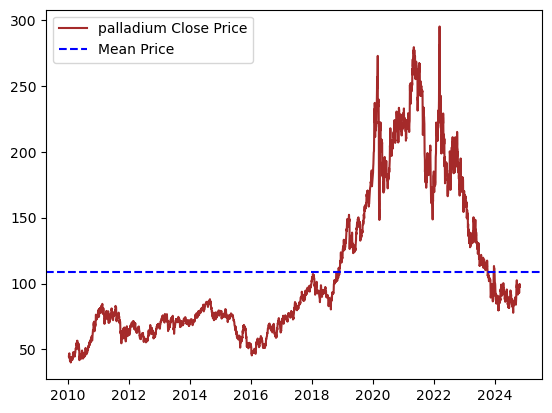

In [177]:
plt.plot(df_palladium['date'], df_palladium['palladium close'], label='palladium Close Price', color='brown')
plt.axhline(df_palladium['palladium close'].mean(), color='b', linestyle='dashed', label='Mean Price')
plt.legend()
plt.show()

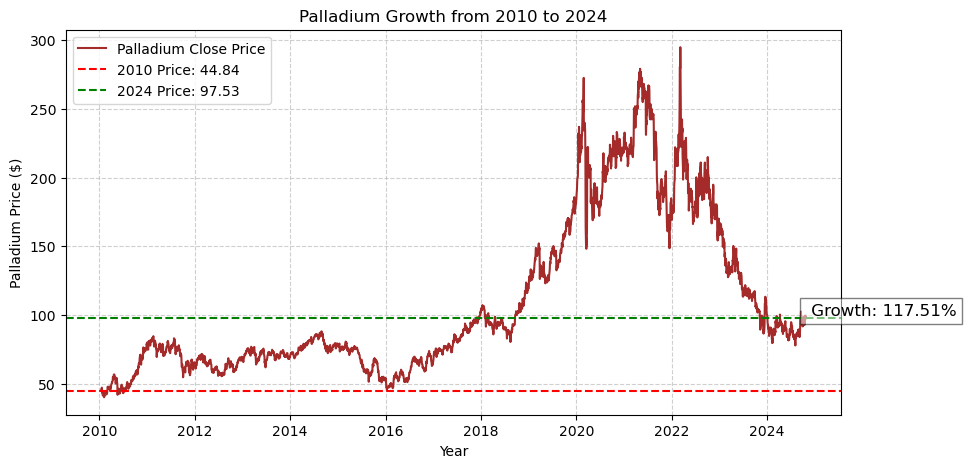

In [83]:
# % การเติบโตตั้งแต่ ปี 2010 - 2024 ของ  palladium

# หาค่าเริ่มต้นและค่าสุดท้ายของ Palladium
initial_value_palladium = df_palladium[df_palladium['date'].dt.year == 2010]['palladium close'].iloc[0]
final_value_palladium = df_palladium[df_palladium['date'].dt.year == 2024]['palladium close'].iloc[-1]

# คำนวณเปอร์เซ็นต์การเติบโต
growth_percentage_palladium = ((final_value_palladium - initial_value_palladium) / initial_value_palladium) * 100

# Plot กราฟการเติบโตของ Palladium
plt.figure(figsize=(10,5))
plt.plot(df_palladium['date'], df_palladium['palladium close'], label="Palladium Close Price", color='brown')

# เพิ่มเส้นแนวนอนแสดงราคาเริ่มต้นและปัจจุบัน
plt.axhline(initial_value_palladium, color='red', linestyle='dashed', label=f"2010 Price: {initial_value_palladium:.2f}")
plt.axhline(final_value_palladium, color='green', linestyle='dashed', label=f"2024 Price: {final_value_palladium:.2f}")

# เพิ่มข้อความแสดงเปอร์เซ็นต์การเติบโตบนกราฟ
plt.text(df_palladium['date'].iloc[-1], final_value_palladium, f" Growth: {growth_percentage_palladium:.2f}%", 
         horizontalalignment='left', verticalalignment='bottom', fontsize=12, color='black', bbox=dict(facecolor='white', alpha=0.5))

# ตั้งค่า Label และ Title
plt.xlabel("Year")
plt.ylabel("Palladium Price ($)")
plt.title("Palladium Growth from 2010 to 2024")

# แสดง Legend
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# แสดงกราฟ
plt.show()

In [105]:
df.columns

Index(['sp500 open', 'sp500 high', 'sp500 low', 'sp500 close', 'sp500 volume',
       'sp500 high-low', 'nasdaq open', 'nasdaq high', 'nasdaq low',
       'nasdaq close', 'nasdaq volume', 'nasdaq high-low', 'us_rates_%', 'CPI',
       'usd_chf', 'eur_usd', 'GDP', 'silver open', 'silver high', 'silver low',
       'silver close', 'silver volume', 'silver high-low', 'oil open',
       'oil high', 'oil low', 'oil close', 'oil volume', 'oil high-low',
       'platinum open', 'platinum high', 'platinum low', 'platinum close',
       'platinum volume', 'platinum high-low', 'palladium open',
       'palladium high', 'palladium low', 'palladium close',
       'palladium volume', 'palladium high-low', 'gold open', 'gold high',
       'gold low', 'gold close', 'gold volume', 'year', 'month'],
      dtype='object')

C:\Users\por-n\AppData\Local\Temp\ipykernel_7284\712230928.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_assets.dropna(axis=0, inplace=True)


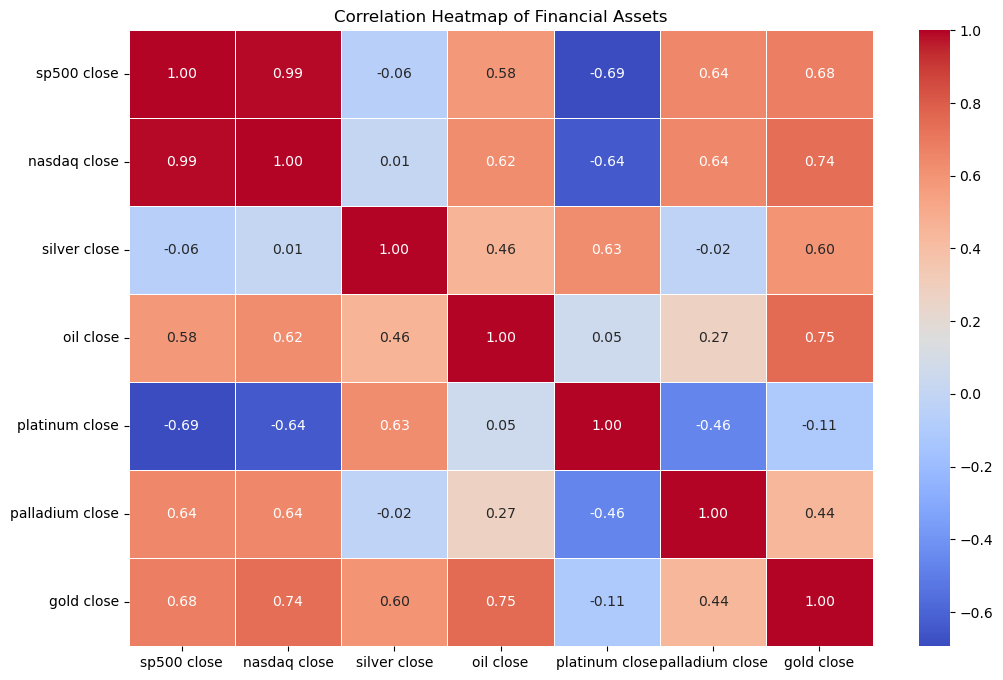

In [27]:
df_assets = df.filter(like="close")
df_assets.dropna(axis=0, inplace=True)
# คำนวณ Correlation Matrix
correlation_matrix = df_assets.corr()

# Plot Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Financial Assets")
plt.show()

In [32]:
df_sp500.columns

Index(['date', 'sp500 open', 'sp500 low', 'sp500 high', 'sp500 close',
       'sp500 volume'],
      dtype='object')

In [18]:
X = df_sp500[['sp500 open', 'sp500 high', 'sp500 low', 'sp500 volume']].values
y = df_sp500['sp500 close'].values

In [19]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ตั้งค่า Time Series Split (แบ่งข้อมูลเป็น 5 fold)
tscv = TimeSeriesSplit(n_splits=5)

# เก็บค่าผลลัพธ์ของแต่ละรอบ
mae_scores, mse_scores, rmse_scores, r2_scores = [], [], [], []

# ใช้ Cross Validation กับ Time Series Split
for train_index, test_index in tscv.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # สร้างและ Train โมเดล Linear Regression
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    #  คำนวณค่าความแม่นยำของโมเดล
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # บันทึกค่า MAE, MSE, RMSE, R² Score
    mae_scores.append(mae)
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

In [20]:
print(f"Average MAE: {np.mean(mae_scores):.2f}")
print(f"Average MSE: {np.mean(mse_scores):.2f}")
print(f"Average RMSE: {np.mean(rmse_scores):.2f}")
print(f"Average R² Score: {np.mean(r2_scores):.2%}")

Average MAE: 0.77
Average MSE: 1.53
Average RMSE: 1.10
Average R² Score: 99.85%


In [180]:
# แสดงค่าที่พยากรณ์ได้เทียบกับค่าจริง
result = list(zip(y_test, y_pred_test))  # รวมผลลัพธ์จริงกับค่าที่พยากรณ์

# แสดงผล 10 ตัวอย่างแรก
for i, (actual, predicted) in enumerate(result[: 10]):
    print(f"Test Sample {i+1}: Actual Price: {actual:.2f} | Predicted Price: {predicted:.2f}")


Test Sample 1: Actual Price: 398.17 | Predicted Price: 399.44
Test Sample 2: Actual Price: 399.09 | Predicted Price: 398.22
Test Sample 3: Actual Price: 392.75 | Predicted Price: 398.21
Test Sample 4: Actual Price: 392.34 | Predicted Price: 391.41
Test Sample 5: Actual Price: 401.72 | Predicted Price: 401.29
Test Sample 6: Actual Price: 400.09 | Predicted Price: 401.52
Test Sample 7: Actual Price: 408.32 | Predicted Price: 405.23
Test Sample 8: Actual Price: 391.86 | Predicted Price: 393.56
Test Sample 9: Actual Price: 389.46 | Predicted Price: 392.09
Test Sample 10: Actual Price: 389.63 | Predicted Price: 386.33


In [185]:
df2 = pd.read_csv("Download Data - FUND_US_ARCX_SPY.csv")

In [191]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    22 non-null     object 
 1   Open    22 non-null     float64
 2   High    22 non-null     float64
 3   Low     22 non-null     float64
 4   Close   22 non-null     float64
 5   Volume  22 non-null     object 
dtypes: float64(4), object(2)
memory usage: 1.2+ KB


In [192]:
df2['Date'] = pd.to_datetime(df2['Date'])

In [193]:
df2.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')

In [195]:
df2.dropna(inplace=True)

In [197]:
df2['Volume'] = df2['Volume'].str.replace(',', '').astype(float)

In [198]:
# เลือก Features ที่ต้องใช้ในการพยากรณ์จาก df_new
X_new = df2[['Open', 'High', 'Low', 'Volume']].values  

# ใช้โมเดลที่ฝึกแล้วทำนาย
y_pred_new = model.predict(X_new)

# เพิ่มคอลัมน์ราคาที่พยากรณ์ลงใน DataFrame
df2['Predicted Close'] = y_pred_new


In [201]:
df2.head()

,Date,Open,High,Low,Close,Volume,Predicted Close
0,2025-03-12,562.17,563.11,553.69,558.87,69588172.0,556.402849
1,2025-03-11,559.40,564.02,552.02,555.92,88102109.0,557.505434
2,2025-03-10,567.59,569.54,555.59,560.58,99326625.0,559.817133
3,2025-03-07,570.90,577.39,565.63,575.92,81158812.0,572.226997
4,2025-03-06,575.48,580.17,570.12,572.71,80094875.0,575.268093


In [206]:
mae = mean_absolute_error(df2['Close'], df2['Predicted Close'])
mse = mean_squared_error(df2['Close'], df2['Predicted Close'])
rmse = np.sqrt(mse)
r2 = r2_score(df2['Close'], df2['Predicted Close'])

# แสดงผลลัพธ์
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.2%}")

MAE: 1.67
MSE: 3.84
RMSE: 1.96
R² Score: 98.75%


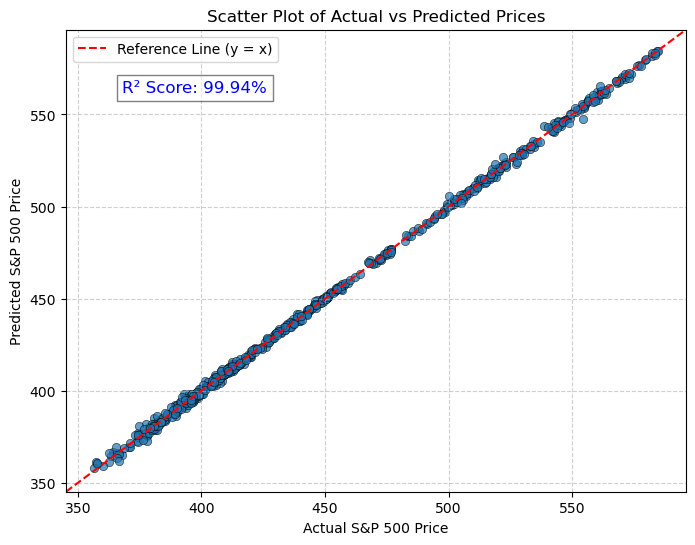

In [121]:
import seaborn as sns
import matplotlib.pyplot as plt

# สร้าง Scatter Plot พร้อมแสดงรายละเอียด
plt.figure(figsize=(8,6))
ax = sns.scatterplot(x=y_test, y=y_pred_test, alpha=0.7, edgecolor='black')

# เพิ่มเส้นอ้างอิง y = x (เส้นไดอะแกน)
plt.axline([min(y_test), min(y_test)], [max(y_test), max(y_test)], 
           color='red', linestyle='dashed', label="Reference Line (y = x)")

# คำนวณค่า R² Score
r2 = r2_score(y_test, y_pred_test)

# กำหนดตำแหน่งแสดงค่า R² Score ให้อยู่ด้านบนขวาของกราฟ
plt.text(min(y_test) + (max(y_test) - min(y_test)) * 0.05,  # เลื่อนไปทางขวา 5% ของช่วงค่า
         max(y_pred_test) - (max(y_pred_test) - min(y_pred_test)) * 0.1,  # เลื่อนลงล่าง 10% ของช่วงค่า
         f'R² Score: {r2:.2%}', fontsize=12, color='blue', 
         bbox=dict(facecolor='white', alpha=0.5))

# เพิ่ม Label และ Title
plt.xlabel("Actual S&P 500 Price")
plt.ylabel("Predicted S&P 500 Price")
plt.title("Scatter Plot of Actual vs Predicted Prices")

# เพิ่ม Grid
plt.grid(True, linestyle="--", alpha=0.6)

# เพิ่ม Legend
plt.legend()

# แสดงกราฟ (รันโค้ดนี้เพื่อแสดง) 
plt.show()


In [29]:
from sklearn.cluster import KMeans
import seaborn as sns

# เลือกเฉพาะคอลัมน์ราคาปิดของสินทรัพย์ทั้งหมด
df_assets = df.filter(like="close")
df_assets.dropna(axis=0, inplace=True)

# ใช้ K-Means จัดกลุ่มสินทรัพย์เป็น 3 กลุ่ม
model = KMeans(n_clusters=3, random_state=0)
clusters = model.fit_predict(df_assets.T)  # ใช้ Transpose (T) เพื่อให้สินทรัพย์เป็น Feature

# เพิ่มผลลัพธ์ลง DataFrame
asset_clusters = pd.DataFrame({'Asset': df_assets.columns, 'Cluster': clusters})

# แสดงผล
print(asset_clusters.sort_values(by="Cluster"))


             Asset  Cluster
2     silver close        0
3        oil close        0
0      sp500 close        1
1     nasdaq close        1
4   platinum close        2
5  palladium close        2
6       gold close        2


C:\Users\por-n\AppData\Local\Temp\ipykernel_7284\3043228787.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_assets.dropna(axis=0, inplace=True)
C:\Users\por-n\anaconda3\envs\datasci_basic\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [179]:
asset_clusters

,Asset,Cluster
0,sp500 close,1
1,nasdaq close,1
2,silver close,0
3,oil close,0
4,platinum close,2
5,palladium close,2
6,gold close,2


In [151]:
from sklearn.metrics import silhouette_score

# คำนวณ silhouette score
silhouette_avg = silhouette_score(df_assets.T, clusters)

# แสดงผล
print(f"Silhouette Score: {silhouette_avg:.2f}")


Silhouette Score: 0.49


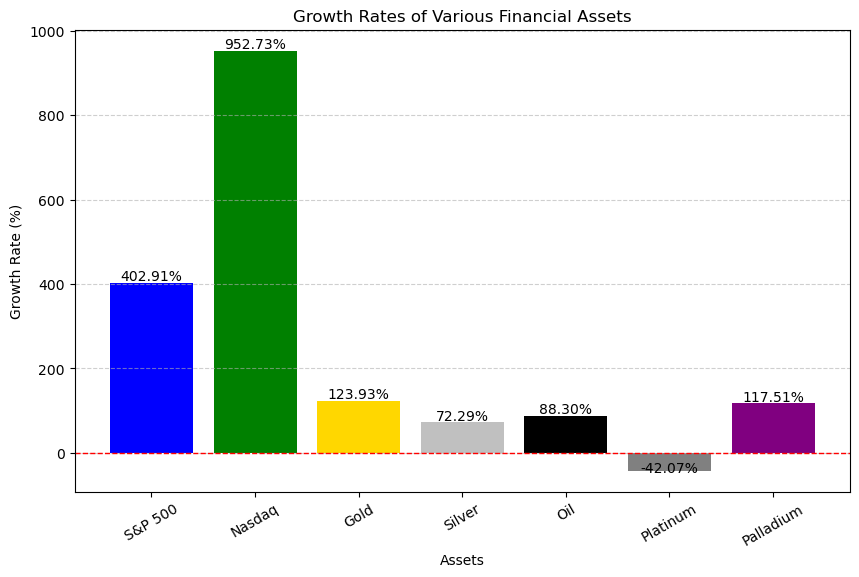

In [209]:
import matplotlib.pyplot as plt

# ✅ ข้อมูลการเติบโตของสินทรัพย์
assets = ["S&P 500", "Nasdaq", "Gold", "Silver", "Oil", "Platinum", "Palladium"]
growth_rates = [402.91, 952.73, 123.93, 72.29, 88.30, -42.07, 117.51]

# ✅ Plot กราฟแท่ง (Bar Chart)
plt.figure(figsize=(10,6))
plt.bar(assets, growth_rates, color=['blue', 'green', 'gold', 'silver', 'black', 'gray', 'purple'])

# ✅ เพิ่มรายละเอียดในกราฟ
plt.xlabel("Assets")
plt.ylabel("Growth Rate (%)")
plt.title("Growth Rates of Various Financial Assets")
plt.axhline(0, color='red', linestyle='dashed', linewidth=1)  # เส้นแกน 0%
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# ✅ แสดงค่าแต่ละแท่งบนกราฟ
for i, rate in enumerate(growth_rates):
    plt.text(i, rate + (5 if rate > 0 else -5), f"{rate:.2f}%", ha='center', fontsize=10, color="black")

# ✅ แสดงกราฟ
plt.show()


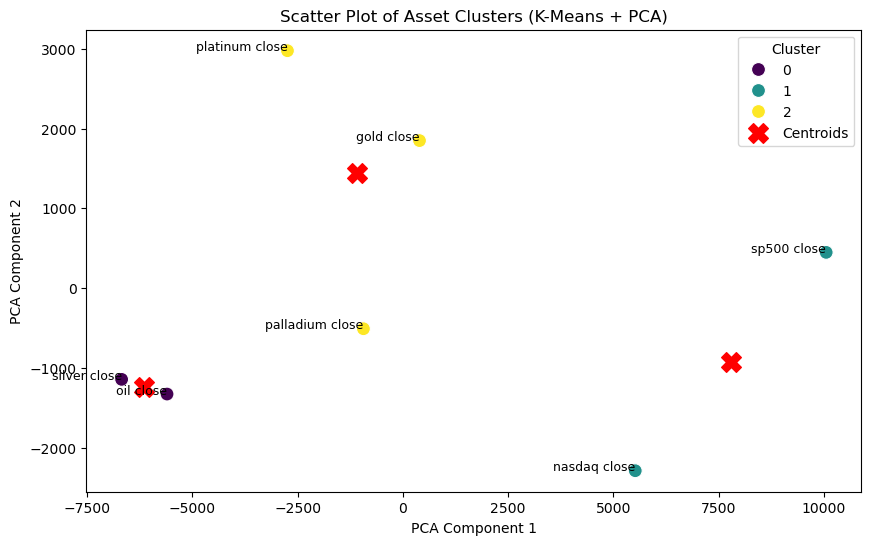

In [30]:
# ✅ โหลดไลบรารีที่จำเป็น
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ✅ ใช้ PCA ลดมิติข้อมูลจาก N มิติ เหลือ 2 มิติ
pca = PCA(n_components=2)
pca_result = pca.fit_transform(df_assets.T)  # ใช้ Transpose (T) เพื่อให้สินทรัพย์เป็น Feature

# ✅ คำนวณตำแหน่งจุดศูนย์กลางของ Cluster (Centroids)
centroids = pca.transform(model.cluster_centers_)  # แปลงจุดศูนย์กลางเป็น 2D

# ✅ สร้าง DataFrame สำหรับ Plot
df_pca = pd.DataFrame(pca_result, columns=["PCA1", "PCA2"])
df_pca["Cluster"] = clusters
df_pca["Asset"] = df_assets.columns

# ✅ Plot Scatter Plot แสดงกลุ่มสินทรัพย์หลังทำ PCA
plt.figure(figsize=(10,6))
sns.scatterplot(x=df_pca["PCA1"], y=df_pca["PCA2"], hue=df_pca["Cluster"], palette="viridis", s=100)

# ✅ เพิ่ม Label ของสินทรัพย์แต่ละตัว
for i, asset in enumerate(df_pca["Asset"]):
    plt.text(df_pca["PCA1"][i], df_pca["PCA2"][i], asset, fontsize=9, ha='right')

# ✅ แสดงจุดศูนย์กลางของ Cluster (K-Means Centroids)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label="Centroids")

# ✅ เพิ่มรายละเอียดในกราฟ
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Scatter Plot of Asset Clusters (K-Means + PCA)")
plt.legend(title="Cluster")

# ✅ แสดงกราฟ
plt.show()
